# AF488⁺ cells at and across the junction of WT3 and GD1 assembloids

**Question.** Do assembloids of WT3 and GD1 differ in the number of AF488-labelled (AF488⁺) cells at the junction between the two organoids, in the number that crossed the junction into the partner organoid, and in where the crossed cells lie?

**Sample.** 614 sections that passed the pre-screen and whose junction line was accepted (or redrawn by hand) in the Junction review: **WT3 265 sections on 17 slides, GD1 349 sections on 19 slides**, from three experiments (8, 9 and 10), each with both genotypes. WT2 is listed in the scan file list but is not part of this study; it was left out by design, before any analysis. How the 614 were reached, and how the automated count compares with human counts, is in `01_validation.ipynb`.

**Counting method.** An AF488⁺ cell is one **object of the AF488 mask**: the AF488 channel (brightest plane over z) is smoothed (Gaussian, 0.5 µm), its local background (Gaussian, σ = 20 µm) is subtracted, and the result is thresholded inside the tissue at the median + 5 robust SD (1.4826 × MAD) of the section's tissue; objects smaller than 20 µm² are removed and holes smaller than 10 µm² filled. One connected object counts as one labelled cell body, so no nuclear segmentation or per-cell intensity rule is involved. The junction line and the junction region (the counting band along it) come from the cells-analysis run.

**Where a cell lies.** Each section has a *home side* of the junction line (the organoid holding most of the run's AF488⁺ cells beside the line) and a *far side*. An object **crossed** when it lies beside the junction line, 2–300 µm past it on the far side; it is **on the home side** when it lies 2–300 µm from the line on the home side. Counts are divided by the length of the junction line (per mm). For the crossed objects of a section, the mean distance to the organoid edge (that of the nearest segmented cell) and the mean distance past the line are recorded when the section has at least 3 crossed objects.

**Statistics.** Sections of one slide are not independent, so every comparison uses a linear mixed model with genotype and experiment as fixed effects and slide as a random intercept (REML; Wald 95 % confidence intervals). Counts per mm are analysed as log(1 + y) and reported as the fold WT3 / GD1; the share crossed and the distances as the difference WT3 − GD1. **Primary outcome: AF488⁺ cells that crossed, per mm of junction.** It was declared primary after exploratory analysis of the same data (`notebooks/dataset/03`–`05`); it was not pre-registered. All other outcomes are secondary, with the Holm correction across the seven of them. Robustness: leaving out one experiment or one slide at a time, a slide-level test (n = slides), and adjustment for section covariates.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# ---------------------------------------------------------------- Settings: change these
DATA = Path(r"D:\Slidescanner extracted")
RUN = DATA / "cells_analysis" / "2026-10-28_090440 re-scored"      # the cells-analysis run (614 sections)
OUT = DATA / "run_analysis_20261028"                                # caches written by notebooks/dataset
MASKS = OUT / "af488_mask"                                          # af488_masks.py: the AF488 mask, every section
FIGURES = OUT / "figures_official"
DESIGN_CSV = DATA / "Image_File_List.csv"
GENOTYPES = ["WT3", "GD1"]       # WT2 is in the file list but not part of this study
CHANNEL = "AF488"
METHOD_MASK = "kmad5"            # the counting method: AF488 mask objects, Gaussian 20 µm background, median + 5 SD
GAP_UM, NEAR_UM = 2.0, 300.0     # crossed = beside the junction line, 2–300 µm past it
SEED, N_BOOT = 0, 2000
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)

# Publication style: black and greys only for data; images in the stain's own colour.
INK, DARK, MID, LIGHT = "#000000", "#4d4d4d", "#8c8c8c", "#d9d9d9"
GENOTYPE_FACE = {"WT3": DARK, "GD1": "#ffffff"}        # filled vs open, black edge on both
GENOTYPE_MARKER = {"WT3": "o", "GD1": "s"}
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "normal",
    "axes.labelsize": 9, "axes.linewidth": 1.0, "axes.edgecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0, "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.color": INK, "ytick.color": INK, "axes.prop_cycle": mpl.cycler(color=[INK, MID, DARK, LIGHT]),
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 120,
    "savefig.dpi": 600, "savefig.bbox": "tight", "svg.fonttype": "none", "pdf.fonttype": 42,
})


def save(fig, name):
    """Write the figure as vector (svg, pdf) and 600 dpi png into FIGURES."""
    if SAVE_FIGURES:
        for ext in ("svg", "pdf", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def panel_letters(axes, x=-0.22, y=1.04):
    for letter, ax in zip("abcdefghijklmnop", np.ravel(axes)):
        ax.text(x, y, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom")


def p_text(p):
    return "n.s." if not np.isfinite(p) or p >= 0.05 else ("P < 0.001" if p < 0.001 else f"P = {p:.3f}")


design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design = design[design["Genotype"].isin(GENOTYPES)].copy()
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)


## Sections, sides and counts

The run's sections are joined to the design table (genotype, experiment, slide). Each section's home side is set from the run's AF488⁺ cells as in `notebooks/dataset/04`; the mask objects (`af488_mask/<section>/objects.parquet`, mask `kmad5`) are then sorted into the junction region, the crossed zone and the home zone.

In [2]:
from IPython.display import display
import statsmodels.formula.api as smf
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)   # slide variance near 0 in a few refits: the fit is still valid

# ---------------------------------------------------------------- Settings for this notebook
CACHE = OUT / "cache"            # per-section cell tables (dataset/03): place, side of the line, distance to the edge
MIN_EDGE = 3                     # a section's distance outcomes need at least this many crossed cells
MIN_SHARE = 5                    # the share crossed needs at least this many AF488+ cells 2–300 µm either side
WIDTH_STEP_UM, WIDTH_MIN_CELLS = 25.0, 20   # local half-width of the organoid, per 25 µm step past the line
REFERENCE, OTHER = "GD1", "WT3"  # every fold and difference is WT3 against GD1
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"
# ----------------------------------------------------------------------------------------------


def read_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    return {"name": info["sample"], "region by": info.get("region_by"),
            "junction length (µm)": info.get("junction_length_um", np.nan), "cells in section": info.get("n_cells_section")}


# The analysed sections: those of the cells-analysis run, with their design (genotype, experiment, slide).
sections = pd.DataFrame([read_section(p) for p in sorted((RUN / "cells").glob("*.json"))])
review = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts")
review = review[review["Channel"] == CHANNEL].set_index("Sample")
sections["QC status"] = sections["name"].map(review["Review status"])
n_run = len(sections)
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name", how="inner").set_index("name")
sections["length (mm)"] = sections["junction length (µm)"] / 1000
sections["QC ok"] = sections["QC status"].eq("ok")
sections["hand-drawn region"] = sections["region by"].eq("by hand")
scales = pd.read_csv(OUT / "section_scales.csv").set_index("name")      # written by dataset/04
sections["assembloid length (µm)"] = scales["assembloid length (µm)"]
print(f"{n_run} sections in the run, {len(sections)} with a WT3 / GD1 design entry, on {sections['slide'].nunique()} slides")
display(sections.groupby(["Genotype", "Experiment"]).agg(sections=("slide", "size"), slides=("slide", "nunique"))
        .unstack("Genotype").fillna(0).astype(int))

# Each section's cells (from the run): which side of the line AF488 is at home on, and each cell's distance to the edge.
cells = {}
for name in sections.index:
    c = pd.read_parquet(CACHE / f"{name}.parquet", columns=["y", "x", "region", "d", "beside", "edge", "AF488 positive"])
    pos = c["AF488 positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    # AF488's home is the side holding most of the run's AF488+ cells (as dataset/04); "away" > 0 is the far side.
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
    sections.at[name, "sign"] = sign
    cells[name] = c


614 sections in the run, 614 with a WT3 / GD1 design entry, on 36 slides


sections      slides    
Genotype        GD1  WT3    GD1 WT3
Experiment                         
10              122  100      6   6
8               111   80      6   5
9               116   85      7   6

In [3]:
WIDTH_EDGES = np.arange(0, NEAR_UM + WIDTH_STEP_UM, WIDTH_STEP_UM)


def half_widths(away, beside, edge):
    """Per 25 µm step past the line: the organoid's half-width, as the 99th percentile of the cells' distance to the edge."""
    step = np.digitize(away, WIDTH_EDGES) - 1
    out = np.full(len(WIDTH_EDGES) - 1, np.nan)
    for k in range(len(out)):
        here = beside & (step == k) & (edge > 0)
        if here.sum() >= WIDTH_MIN_CELLS:
            out[k] = np.percentile(edge[here], 99)
    return out


def width_at(away, widths):
    step = np.digitize(away, WIDTH_EDGES) - 1
    ok = (step >= 0) & (step < len(widths))
    out = np.full(len(away), np.nan)
    out[ok] = widths[step[ok]]
    return out


def mask_objects(name, sign):
    """The section's AF488 mask objects (kmad5), with their side, zone and (for crossed ones) distance to the edge."""
    o = pd.read_parquet(MASKS / name / "objects.parquet")
    o = o[o["mask"] == METHOD_MASK].reset_index(drop=True)
    o["away"] = o["Distance to the junction line (µm)"].to_numpy(float) * sign
    beside = o["Beside the junction line"].to_numpy(bool)
    o["crossed"] = beside & (o["away"] > GAP_UM) & (o["away"] <= NEAR_UM)
    o["home"] = beside & (o["away"] < -GAP_UM) & (o["away"] >= -NEAR_UM)
    return o


def section_outcomes(name, s):
    c = cells[name]
    o = mask_objects(name, s["sign"])
    x = o[o["crossed"]]
    # An object's distance to the organoid edge is that of the nearest segmented cell (cells lie ~10 µm apart).
    _, nearest = cKDTree(c[["y", "x"]].to_numpy()).query(x[["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy())
    edge = c["edge"].to_numpy(float)[nearest] if len(x) else np.array([])
    widths = half_widths(c["away"].to_numpy(), c["beside"].to_numpy(bool), c["edge"].to_numpy(float))
    relative = np.clip(edge / width_at(x["away"].to_numpy(), widths), 0, 1) if len(x) else np.array([])
    n_x, n_h, n_r = len(x), int(o["home"].sum()), int(o["In region"].to_numpy(bool).sum())
    for zone in ("crossed", "home"):
        AREAS.append(pd.DataFrame({"Genotype": s["Genotype"], "zone": zone, "area": o.loc[o[zone], "Area (µm²)"]}))
    enough = n_x >= MIN_EDGE
    return {"crossed": n_x, "home": n_h, "in junction": n_r,
            "in junction per mm": n_r / s["length (mm)"], "crossed per mm": n_x / s["length (mm)"],
            "home per mm": n_h / s["length (mm)"],
            "share crossed": n_x / (n_x + n_h) if n_x + n_h >= MIN_SHARE else np.nan,
            "edge (µm)": edge.mean() if enough else np.nan,
            "past line (µm)": x["away"].mean() if enough else np.nan,
            "edge ÷ half-width": np.nanmean(relative) if np.isfinite(relative).sum() >= MIN_EDGE else np.nan,
            "past line ÷ assembloid length": x["away"].mean() / s["assembloid length (µm)"] if enough else np.nan}


AREAS = []
obs = pd.DataFrame({name: section_outcomes(name, s) for name, s in sections.iterrows()}).T.astype(float)
obs = sections[["Genotype", "Experiment", "slide", "QC ok", "hand-drawn region", "length (mm)", "cells in section"]].join(obs)
obs.index.name = "name"
print(f"{len(obs)} sections; AF488+ cells (mask objects) counted: {int(obs['in junction'].sum())} in the junction regions, "
      f"{int(obs['crossed'].sum())} crossed, {int(obs['home'].sum())} on the home side")
print("object area (µm²), median and quartiles, by genotype and zone:")
display(pd.concat(AREAS).groupby(["Genotype", "zone"])["area"].quantile([0.25, 0.5, 0.75]).unstack().round(1))


614 sections; AF488+ cells (mask objects) counted: 12701 in the junction regions, 11102 crossed, 34097 on the home side
object area (µm²), median and quartiles, by genotype and zone:


0.25  0.50   0.75
Genotype zone                      
GD1      crossed  27.3  39.2   64.7
         home     31.5  50.1   88.3
WT3      crossed  29.4  46.7   90.8
         home     31.4  52.6  103.6

## Results

**Table 1.** WT3 against GD1 for every outcome. Mean ± SEM over sections; effect from the mixed model (fold WT3 / GD1 on log(1 + y) for counts per mm; difference WT3 − GD1 otherwise) with its 95 % CI; P from the model, Holm-adjusted across the seven secondary outcomes. Distances are in µm; *local half-width* is the organoid's half-width at the same depth past the line (99th percentile of the cells' distance to the edge in 25 µm steps; 0 = at the surface, ≈ 0.5–1 = towards the middle); *assembloid length* is the length of the assembloid across the line. The distance outcomes need ≥ 3 crossed objects in a section, the share crossed ≥ 5 objects within 300 µm of the line. The table is also saved as `table_1_results.csv`.

In [4]:
# outcome → (scale of the effect, axis label); "fold" = exp of the WT3 − GD1 difference on log(1 + y)
OUTCOMES = {
    "in junction per mm": ("fold", "AF488$^+$ cells in the junction\nregion (per mm of junction)"),
    "crossed per mm": ("fold", "AF488$^+$ cells crossed\n(per mm of junction)"),
    "home per mm": ("fold", "AF488$^+$ cells on the home side\n(per mm of junction)"),
    "share crossed": ("difference", "Share crossed\ncrossed / (crossed + home)"),
    "edge (µm)": ("difference", "Crossed cells: distance to\nthe organoid edge (µm)"),
    "past line (µm)": ("difference", "Crossed cells: distance\npast the line (µm)"),
    "edge ÷ half-width": ("difference", "Crossed cells: distance to the\nedge / local half-width"),
    "past line ÷ assembloid length": ("difference", "Crossed cells: distance past the\nline / assembloid length"),
}
PRIMARY = "crossed per mm"
SECONDARY = [o for o in OUTCOMES if o != PRIMARY]


def mixed(frame, column, kind, extra=""):
    """WT3 against GD1: linear mixed model, experiment fixed (+ *extra*), slide as random intercept, REML, Wald 95 % CI."""
    d = frame.copy()
    d["y"] = np.log1p(d[column].astype(float)) if kind == "fold" else d[column].astype(float)
    d = d.dropna(subset=["y"])
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)" + extra, d,
                      groups=d["slide"]).fit(reml=True)
    est, (lo, hi) = fit.params[TERM], fit.conf_int().loc[TERM]
    if kind == "fold":
        est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
    return {"effect": est, "CI low": lo, "CI high": hi, "P": fit.pvalues[TERM], "sections": len(d),
            "slides": d["slide"].nunique()}


def effect_text(e, kind, column=""):
    if kind == "fold":
        return f"{e['effect']:.2f}× ({e['CI low']:.2f}–{e['CI high']:.2f})"
    digits = 0 if "µm" in column else 3
    text = f"{e['effect']:+.{digits}f} ({e['CI low']:+.{digits}f} to {e['CI high']:+.{digits}f})"
    return text.replace("-", "−")


def p_exact(p):
    return "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}"


rows = []
for outcome, (kind, _) in OUTCOMES.items():
    y = obs[outcome].astype(float)
    row = {"outcome": outcome, "role": "primary" if outcome == PRIMARY else "secondary",
           "effect scale": "fold WT3 / GD1" if kind == "fold" else "difference WT3 − GD1"}
    for g in GENOTYPES:
        v = y[obs["Genotype"] == g].dropna()
        row[f"{g} mean ± SEM"] = f"{v.mean():.3g} ± {v.std(ddof=1) / np.sqrt(len(v)):.2g}"
    rows.append({**row, **mixed(obs, outcome, kind)})
results = pd.DataFrame(rows).set_index("outcome")
second = results["role"] == "secondary"
results["Holm P"] = np.nan
results.loc[second, "Holm P"] = multipletests(results.loc[second, "P"], method="holm")[1]
results["effect (95 % CI)"] = [effect_text(r, OUTCOMES[o][0], o) for o, r in results.iterrows()]
results["n (WT3 / GD1 sections)"] = [
    "{} / {}".format(*[int(obs.loc[obs["Genotype"] == g, o].notna().sum()) for g in GENOTYPES]) for o in results.index]
TABLE = ["role", "effect scale", "WT3 mean ± SEM", "GD1 mean ± SEM", "effect (95 % CI)", "P", "Holm P",
         "n (WT3 / GD1 sections)", "slides"]
display(results[TABLE].style.format({"P": "{:.2g}", "Holm P": "{:.2g}"}, na_rep="—"))
results[TABLE].to_csv(FIGURES / "table_1_results.csv")


,role,effect scale,WT3 mean ± SEM,GD1 mean ± SEM,effect (95 % CI),P,Holm P,n (WT3 / GD1 sections),slides
outcome,,,,,,,,,
in junction per mm,secondary,fold WT3 / GD1,37 ± 2.3,12.6 ± 0.5,2.32× (1.48–3.63),0.00024,0.0012,265 / 349,36
crossed per mm,primary,fold WT3 / GD1,29.7 ± 1.9,11.7 ± 0.44,1.86× (1.28–2.71),0.0011,—,265 / 349,36
home per mm,secondary,fold WT3 / GD1,89.6 ± 3.4,36.1 ± 1.4,2.62× (2.02–3.40),5.9e-13,4.1e-12,265 / 349,36
share crossed,secondary,difference WT3 − GD1,0.22 ± 0.0085,0.279 ± 0.0093,−0.048 (−0.099 to +0.003),0.064,0.064,265 / 345,36
edge (µm),secondary,difference WT3 − GD1,234 ± 6,304 ± 6.2,−71 (−108 to −34),0.00019,0.0011,252 / 322,36
past line (µm),secondary,difference WT3 − GD1,110 ± 2.2,124 ± 2.3,−14 (−25 to −4),0.0091,0.018,252 / 322,36
edge ÷ half-width,secondary,difference WT3 − GD1,0.504 ± 0.0089,0.562 ± 0.0088,−0.062 (−0.100 to −0.023),0.0016,0.0064,252 / 322,36
past line ÷ assembloid length,secondary,difference WT3 − GD1,0.0553 ± 0.0013,0.0675 ± 0.0015,−0.013 (−0.022 to −0.005),0.0016,0.0064,252 / 322,36


### Figure 1

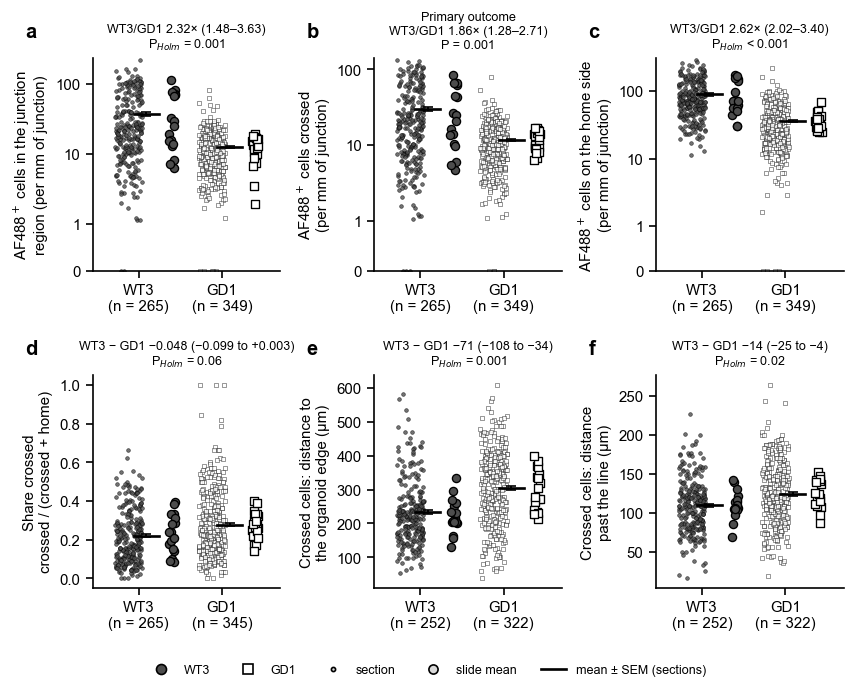

In [5]:
def dot_panel(ax, frame, column, label, kind, e, p, holm, seed=SEED):
    """Sections (small), slide means (large), mean ± SEM (black); the model's effect and P above."""
    rng = np.random.default_rng(seed)
    for k, g in enumerate(GENOTYPES):
        part = frame[frame["Genotype"] == g].dropna(subset=[column])
        y = part[column].astype(float)
        ax.scatter(k - 0.12 + rng.uniform(-0.16, 0.16, len(y)), y, s=5, marker=GENOTYPE_MARKER[g],
                   facecolor=GENOTYPE_FACE[g], edgecolor=INK, linewidth=0.3, alpha=0.8, zorder=2)
        slide_y = part.groupby("slide")[column].mean()
        ax.scatter(k + 0.4 + rng.uniform(-0.04, 0.04, len(slide_y)), slide_y, s=24, marker=GENOTYPE_MARKER[g],
                   facecolor=GENOTYPE_FACE[g], edgecolor=INK, linewidth=0.8, zorder=3)
        m, sem = y.mean(), y.std(ddof=1) / np.sqrt(len(y))
        ax.errorbar(k + 0.09, m, yerr=sem, fmt="none", ecolor=INK, elinewidth=1.2, capsize=3, zorder=4)
        ax.plot([k - 0.06, k + 0.24], [m, m], color=INK, lw=1.6, zorder=4)
    n = [int(frame.loc[frame["Genotype"] == g, column].notna().sum()) for g in GENOTYPES]
    ax.set_xticks([0, 1], [f"{g}\n(n = {a})" for g, a in zip(GENOTYPES, n)])
    ax.set_xlim(-0.55, 1.7)
    ax.set_ylabel(label)
    if kind == "fold":
        ax.set_yscale("symlog", linthresh=1, linscale=0.6)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.set_ylim(bottom=0)
    head = ("WT3/GD1 " if kind == "fold" else "WT3 − GD1 ") + effect_text(e, kind, column)
    ptxt = p_exact(p) if holm is None or not np.isfinite(holm) else p_exact(holm).replace("P", "P$_{Holm}$")
    lead = "Primary outcome\n" if column == PRIMARY else ""
    ax.set_title(f"{lead}{head}\n{ptxt}", fontsize=7.5, loc="center", fontweight="normal")


FIG1 = ["in junction per mm", "crossed per mm", "home per mm", "share crossed", "edge (µm)", "past line (µm)"]
fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.6))
for ax, outcome in zip(axes.flat, FIG1):
    r = results.loc[outcome]
    kind, label = OUTCOMES[outcome]
    dot_panel(ax, obs, outcome, label, kind, r, r["P"], r["Holm P"])
handles = [mpl.lines.Line2D([], [], ls="", marker=GENOTYPE_MARKER[g], markerfacecolor=GENOTYPE_FACE[g],
                            markeredgecolor=INK, label=g) for g in GENOTYPES]
handles += [mpl.lines.Line2D([], [], ls="", marker="o", ms=2.5, markerfacecolor=LIGHT, markeredgecolor=INK,
                             label="section"),
            mpl.lines.Line2D([], [], ls="", marker="o", ms=5.5, markerfacecolor=LIGHT, markeredgecolor=INK,
                             label="slide mean"),
            mpl.lines.Line2D([], [], color=INK, lw=1.6, label="mean ± SEM (sections)")]
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03), fontsize=7.5)
panel_letters(axes, x=-0.36, y=1.08)
fig.tight_layout(rect=(0, 0.03, 1, 1), h_pad=1.6)
save(fig, "figure_1_wt3_vs_gd1")
plt.show()


**Figure 1. WT3 assembloids have more AF488⁺ cells at and across the junction than GD1 assembloids, and their crossed cells lie nearer the organoid surface.** (**a**) AF488⁺ cells in the junction region per mm of junction line. (**b**) AF488⁺ cells that crossed the junction (2–300 µm past the line, in the partner organoid) per mm — the primary outcome. (**c**) AF488⁺ cells on the home side (2–300 µm from the line) per mm. (**d**) Share of AF488⁺ cells near the line that crossed, crossed / (crossed + home). (**e**) Mean distance of a section's crossed cells to the organoid edge. (**f**) Mean distance of a section's crossed cells past the line. Small markers: sections (WT3 filled, GD1 open); large markers: slide means; black: mean ± SEM of sections. Counts on a symmetric log axis (linear below 1). Above each panel: fold WT3 / GD1 (a–c) or difference WT3 − GD1 (d–f) with 95 % CI from the linear mixed model (genotype and experiment fixed, slide random; counts as log(1 + y)); P unadjusted for the primary outcome (b), Holm-adjusted across the seven secondary outcomes otherwise. n = sections (265 WT3 / 349 GD1 on 17 / 19 slides; fewer in d–f, which need ≥ 5 or ≥ 3 cells).

**What it shows (5 Nov 2026).**
- **Primary outcome.** WT3 sections had 29.7 ± 1.9 crossed AF488⁺ cells per mm of junction against 11.7 ± 0.4 in GD1: **1.86-fold (95 % CI 1.28–2.71), P = 0.001**.
- **At the junction and on the home side.** WT3 had 2.32-fold (1.48–3.63) more AF488⁺ cells in the junction region (Holm P = 0.001) and 2.62-fold (2.02–3.40) more on the home side within 300 µm of the line (Holm P < 0.001). The home-side excess is at least as large as the crossed one.
- **Share crossed.** The share of the cells near the line that had crossed did not differ significantly: 0.22 in WT3 against 0.28 in GD1, difference −0.048 (−0.099 to +0.003), Holm P = 0.06. If anything the share is lower in WT3.
- **Where the crossed cells lie.** WT3's crossed cells were 71 µm (34–108) nearer the organoid edge (234 against 304 µm; Holm P = 0.001), also relative to the organoid's local half-width (0.50 against 0.56; −0.062, −0.100 to −0.023; Holm P = 0.006). They lay 14 µm (4–25) less far past the line (110 against 124 µm; Holm P = 0.02), and 0.013 (0.005–0.022) assembloid lengths less (Holm P = 0.006).

## Robustness of the primary outcome

Four checks on crossed AF488⁺ cells per mm, each refitting the mixed model: (a) leaving out one experiment at a time, and each experiment on its own (genotype only, slide random); (b) leaving out one slide at a time (36 refits); (c) adding section covariates — the Junction review's QC status ("ok" against "check" / "fail", from `counts.xlsx`), whether the junction region was drawn by hand (`region_by`), log junction length and log number of segmented cells in the section — one at a time and all together, and within each QC stratum; (d) with slides as the unit: each slide's mean of log(1 + crossed per mm), WT3 against GD1 by Welch's t-test (fold = ratio of the geometric means of 1 + y) and the Mann–Whitney test, and an ordinary regression of the slide means on genotype and experiment.

Primary outcome (crossed per mm), WT3 / GD1 — by experiment:


,effect,CI low,CI high,P,sections,slides
model,,,,,,
all experiments,1.864,1.284,2.707,0.001,614,36
without experiment 8,2.131,1.388,3.274,0.001,423,25
without experiment 9,1.195,0.783,1.822,0.409,413,23
without experiment 10,2.504,1.573,3.986,0.000,392,24
experiment 8 alone,1.377,0.664,2.855,0.391,191,11
experiment 9 alone,4.199,2.846,6.195,0.000,201,13
experiment 10 alone,1.063,0.662,1.705,0.801,222,12


leave one slide out: fold 1.74–2.02, P ≤ 0.0028, P < 0.05 in 36 of 36
Slides as the unit (n = slides):


,primary outcome
fold (Welch),1.849623
CI low,1.122477
CI high,3.047817
Welch P,0.018404
Mann-Whitney P,0.033748
fold (OLS + experiment),1.869497
OLS P,0.003317
slides WT3 / GD1,17 / 19


Primary outcome adjusted for section covariates:


,effect,CI low,CI high,P,sections,slides
model,,,,,,
unadjusted,1.864,1.284,2.707,0.001,614,36
+ QC status (ok),1.884,1.294,2.742,0.001,614,36
+ hand-drawn region,1.832,1.261,2.661,0.001,614,36
+ log junction length,1.850,1.277,2.679,0.001,614,36
+ log cells per section,1.789,1.239,2.584,0.002,614,36
+ all four,1.600,1.137,2.252,0.007,614,36
QC status ok only,1.686,1.144,2.487,0.008,170,25
QC status check / fail only,2.001,1.269,3.155,0.003,444,36


Covariates by genotype (share of sections, or mean):


,qc,hand,length (mm),cells in section
Genotype,,,,
GD1,0.163,0.235,1.095,36669.458
WT3,0.426,0.343,0.980,41846.053


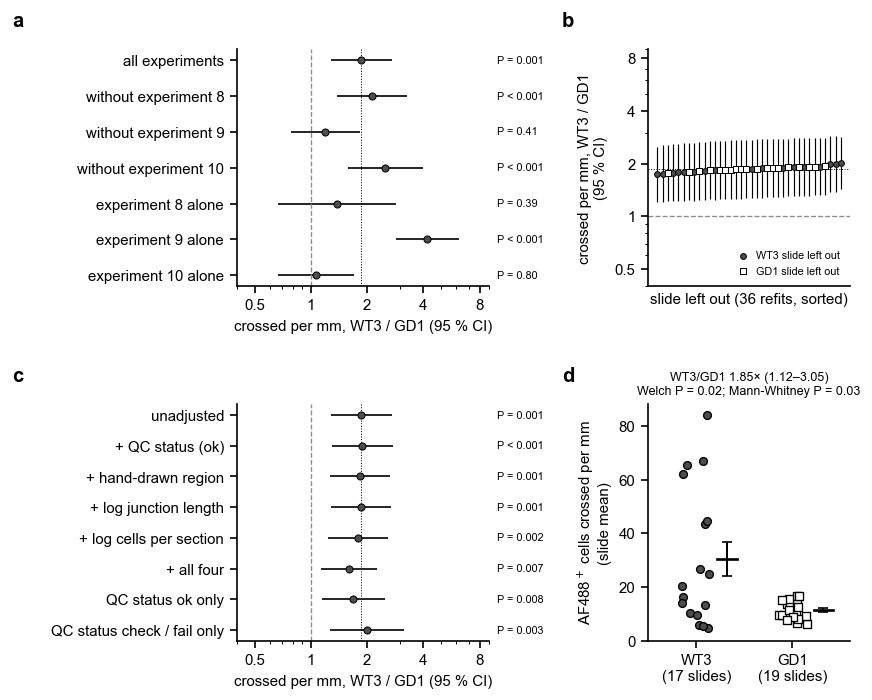

In [6]:
def primary_fit(frame, extra=""):
    return mixed(frame, PRIMARY, "fold", extra)


# (a) experiments: all, each left out, each alone
rows = [{"model": "all experiments", **primary_fit(obs)}]
for e in sorted(obs["Experiment"].unique(), key=int):
    rows.append({"model": f"without experiment {e}", **primary_fit(obs[obs["Experiment"] != e])})
for e in sorted(obs["Experiment"].unique(), key=int):
    part = obs[obs["Experiment"] == e]
    d = part.assign(y=np.log1p(part[PRIMARY]))
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}'))", d, groups=d["slide"]).fit(reml=True)
    lo, hi = np.exp(fit.conf_int().loc[TERM])
    rows.append({"model": f"experiment {e} alone", "effect": np.exp(fit.params[TERM]), "CI low": lo, "CI high": hi,
                 "P": fit.pvalues[TERM], "sections": len(d), "slides": d["slide"].nunique()})
by_experiment = pd.DataFrame(rows).set_index("model")
print("Primary outcome (crossed per mm), WT3 / GD1 — by experiment:")
display(by_experiment.round(3))

# (b) leave one slide out
loso = pd.DataFrame([{"left out": sl, "Genotype": sl.split(" ")[0], **primary_fit(obs[obs["slide"] != sl])}
                     for sl in sorted(obs["slide"].unique())])
print(f"leave one slide out: fold {loso['effect'].min():.2f}–{loso['effect'].max():.2f}, "
      f"P ≤ {loso['P'].max():.2g}, P < 0.05 in {int((loso['P'] < 0.05).sum())} of {len(loso)}")

# (c) slides as the unit: each slide's mean of log(1 + crossed per mm)
slide_means = (obs.assign(t=np.log1p(obs[PRIMARY])).groupby("slide")
               .agg(t=("t", "mean"), mean=(PRIMARY, "mean"), Genotype=("Genotype", "first"),
                    Experiment=("Experiment", "first"), sections=("t", "size")))
a, b = (slide_means.loc[slide_means["Genotype"] == g, "t"] for g in (OTHER, REFERENCE))
welch = stats.ttest_ind(a, b, equal_var=False)
va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
half = stats.t.ppf(0.975, dof) * np.sqrt(va + vb)
ols = smf.ols(f"t ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", slide_means).fit()
slide_level = {"fold (Welch)": np.exp(a.mean() - b.mean()), "CI low": np.exp(a.mean() - b.mean() - half),
               "CI high": np.exp(a.mean() - b.mean() + half), "Welch P": welch.pvalue,
               "Mann-Whitney P": stats.mannwhitneyu(a, b).pvalue,
               "fold (OLS + experiment)": np.exp(ols.params[TERM]), "OLS P": ols.pvalues[TERM],
               "slides WT3 / GD1": f"{len(a)} / {len(b)}"}
print("Slides as the unit (n = slides):")
display(pd.Series(slide_level).to_frame("primary outcome"))

# (d) section covariates added to the model
cov = obs.assign(qc=obs["QC ok"].astype(int), hand=obs["hand-drawn region"].astype(int),
                 log_length=np.log(obs["length (mm)"].astype(float)),
                 log_cells=np.log(obs["cells in section"].astype(float)))
ADJUST = {"unadjusted": "", "+ QC status (ok)": " + qc", "+ hand-drawn region": " + hand",
          "+ log junction length": " + log_length", "+ log cells per section": " + log_cells",
          "+ all four": " + qc + hand + log_length + log_cells"}
adjusted = pd.DataFrame([{"model": k, **primary_fit(cov, v)} for k, v in ADJUST.items()]
                        + [{"model": "QC status ok only", **primary_fit(cov[cov["QC ok"]])},
                           {"model": "QC status check / fail only", **primary_fit(cov[~cov["QC ok"]])}]).set_index("model")
print("Primary outcome adjusted for section covariates:")
display(adjusted.round(3))
cov_by_genotype = cov.groupby("Genotype")[["qc", "hand", "length (mm)", "cells in section"]].mean()
print("Covariates by genotype (share of sections, or mean):")
display(cov_by_genotype.round(3))


def forest(ax, table, labels=None):
    ys = np.arange(len(table))[::-1]
    ax.hlines(ys, table["CI low"], table["CI high"], color=INK, lw=1.0)
    ax.scatter(table["effect"], ys, s=18, marker="o", facecolor=DARK, edgecolor=INK, linewidth=0.6, zorder=3)
    ax.axvline(1, color=MID, lw=0.8, ls="--")
    ax.axvline(table["effect"].iloc[0], color=INK, lw=0.6, ls=":")
    ax.set_yticks(ys, labels if labels is not None else table.index)
    ax.set_xscale("log")
    ax.set_xticks([0.5, 1, 2, 4, 8])
    ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlim(0.4, 9)
    ax.set_xlabel("crossed per mm, WT3 / GD1 (95 % CI)")
    for y, (_, r) in zip(ys, table.iterrows()):
        ax.text(1.03, y, p_exact(r["P"]), ha="left", va="center", fontsize=6.5,
                transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData))


fig = plt.figure(figsize=(7.2, 6.4))
grid = fig.add_gridspec(2, 2, width_ratios=[1.0, 0.8], hspace=0.5, wspace=0.7, left=0.27, right=0.98)
ax_a = fig.add_subplot(grid[0, 0])
forest(ax_a, by_experiment)
ax = ax_b = fig.add_subplot(grid[0, 1])
order = loso.sort_values("effect").reset_index(drop=True)
xs = np.arange(len(order))
ax.vlines(xs, order["CI low"], order["CI high"], color=INK, lw=0.7)
for g in GENOTYPES:
    k = order["Genotype"] == g
    ax.scatter(xs[k], order.loc[k, "effect"], s=12, marker=GENOTYPE_MARKER[g], facecolor=GENOTYPE_FACE[g],
               edgecolor=INK, linewidth=0.6, zorder=3, label=f"{g} slide left out")
ax.axhline(by_experiment.at["all experiments", "effect"], color=INK, lw=0.6, ls=":")
ax.axhline(1, color=MID, lw=0.8, ls="--")
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 4])
ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_ylim(0.4, 9)
ax.set_yticks([0.5, 1, 2, 4, 8])
ax.set_xticks([])
ax.set_xlabel(f"slide left out ({len(order)} refits, sorted)")
ax.set_ylabel("crossed per mm, WT3 / GD1\n(95 % CI)")
ax.legend(loc="lower right", fontsize=6.5, handletextpad=0.2)
ax_c = fig.add_subplot(grid[1, 0])
forest(ax_c, adjusted)
ax = ax_d = fig.add_subplot(grid[1, 1])
rng = np.random.default_rng(SEED)
for k, g in enumerate(GENOTYPES):
    y = slide_means.loc[slide_means["Genotype"] == g, "mean"]
    ax.scatter(k + rng.uniform(-0.15, 0.15, len(y)), y, s=22, marker=GENOTYPE_MARKER[g], facecolor=GENOTYPE_FACE[g],
               edgecolor=INK, linewidth=0.8, zorder=3)
    m, sem = y.mean(), y.std(ddof=1) / np.sqrt(len(y))
    ax.errorbar(k + 0.32, m, yerr=sem, fmt="none", ecolor=INK, elinewidth=1.2, capsize=3)
    ax.plot([k + 0.22, k + 0.42], [m, m], color=INK, lw=1.6)
ax.set_xticks([0, 1], [f"{g}\n({int((slide_means['Genotype'] == g).sum())} slides)" for g in GENOTYPES])
ax.set_xlim(-0.5, 1.6)
ax.set_ylim(bottom=0)
ax.set_ylabel("AF488$^+$ cells crossed per mm\n(slide mean)")
ax.set_title(f"WT3/GD1 {slide_level['fold (Welch)']:.2f}× ({slide_level['CI low']:.2f}–{slide_level['CI high']:.2f})\n"
             f"Welch {p_exact(slide_level['Welch P'])}; Mann-Whitney {p_exact(slide_level['Mann-Whitney P'])}",
             fontsize=7.5)
for letter, ax in zip("abcd", (ax_a, ax_b, ax_c, ax_d)):   # letters at the figure's left of each column
    box = ax.get_position()
    fig.text(0.01 if ax in (ax_a, ax_c) else box.x0 - 0.1, box.y1 + 0.03, letter, fontsize=12, fontweight="bold")
save(fig, "figure_2_robustness")
plt.show()


**Figure 2. The genotype difference in crossed AF488⁺ cells survives leaving out any slide, covariate adjustment and a slide-level test, but it comes mainly from experiment 9.** (**a**) Fold WT3 / GD1 (95 % CI) with all experiments, with one experiment left out, and within each experiment alone. (**b**) The fold with each of the 36 slides left out in turn (sorted; marker = genotype of the slide left out); dotted line, all slides. (**c**) The fold adjusted for section covariates, and within each Junction-review QC stratum. (**d**) Slide means of crossed AF488⁺ cells per mm (n = 17 WT3, 19 GD1 slides), mean ± SEM; fold and Welch / Mann–Whitney P on the slide means of log(1 + y). Dashed line: no difference; P from the mixed model unless stated.

**What it shows (5 Nov 2026).**
- **The effect depends on experiment 9.** Within experiment 9 alone WT3 had 4.20-fold (2.85–6.20, P < 0.001) more crossed cells per mm than GD1; within experiment 8 alone 1.38-fold (0.66–2.86, P = 0.39) and within experiment 10 alone 1.06-fold (0.66–1.71, P = 0.80). Without experiment 9 the fold is 1.20 (0.78–1.82, P = 0.41); without experiment 8, 2.13 (1.39–3.27, P = 0.001); without experiment 10, 2.50 (1.57–3.99, P < 0.001). So the overall difference is carried by one of the three experiments; in the other two it is small and not significant. The direction is the same (WT3 ≥ GD1) in all three.
- **No single slide carries it.** Leaving out any one slide gives folds of 1.74–2.02, every one with P ≤ 0.003.
- **Section covariates do not explain it.** WT3 sections were more often QC "ok" in the review (43 % against 16 %) and more often had a hand-drawn region (34 % against 24 %). Adjusted for QC status, hand-drawn region, junction length and cells per section together, the fold is 1.60 (1.14–2.25, P = 0.007); one covariate at a time, 1.79–1.88. Within QC "ok" sections only it is 1.69 (1.14–2.49, P = 0.008; 170 sections, 25 slides), within "check" / "fail" 2.00 (1.27–3.16, P = 0.003).
- **Slides as the unit.** With one value per slide (n = 17 / 19) the fold is 1.85 (1.12–3.05), Welch P = 0.018, Mann–Whitney P = 0.034; with experiment in an ordinary regression on the slide means, 1.87, P = 0.003. The WT3 slides are much more spread than the GD1 slides: the highest WT3 slide means come from experiment 9.

## Representative images

For each genotype and experiment, the section whose primary outcome lies nearest its genotype's median (WT3 17.6, GD1 10.0 crossed per mm) is shown. The crop is centred on the midpoint of the junction line (by length), not chosen for its content: 600 µm across the line and 400 µm along it. Only the crop (+ 60 µm margin) of AF488 is read, with the nuclear stain at 1/8 resolution for the tissue outline; the mask is recomputed there with the section's stored threshold (`af488_mask/<section>/summary.json`), as `notebooks/dataset/af488_masks.py` does on the whole section (on five test crops of one section, 86–100 % of the recomputed objects matched a stored one within 1 µm; the others touch the crop's border). A recomputed object is shown as crossed when its centroid lies within 2 µm of a stored crossed object. Each crop is turned (transposed and / or mirrored, both rigid) so that the line runs top to bottom and the home side is on the left.

,Genotype,slide,crossed per mm,crossed,in junction per mm,home per mm,share crossed
name,,,,,,,
2025_09_26_Asssembloid_022-021_s7,WT3,WT3 e8 s5,17.21,13.0,21.18,39.72,0.30
2025_09_26_Asssembloid_028-027_s16,WT3,WT3 e9 s6,17.05,9.0,47.35,178.03,0.09
2025_09_26_Asssembloid_033-032_s8,WT3,WT3 e10 s3,17.63,21.0,20.15,53.72,0.25
2025_09_26_Asssembloid_040-039_s27,GD1,GD1 e8 s3,9.95,15.0,11.28,19.91,0.33
2025_09_26_Asssembloid_047-046_s20,GD1,GD1 e9 s3,9.90,14.0,12.02,21.21,0.32
2025_09_26_Asssembloid_055-054_s15,GD1,GD1 e10 s4,10.02,12.0,10.85,49.25,0.17


genotype medians of crossed per mm: {'GD1': 10.02, 'WT3': 17.63}


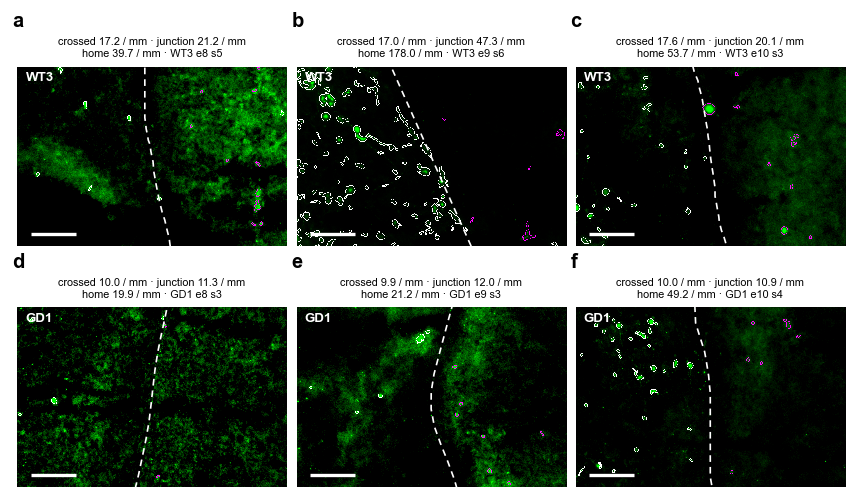

In [7]:
import logging

from scipy import ndimage
from skimage.measure import label as label_objects, regionprops_table
from skimage.morphology import remove_small_holes, remove_small_objects
from skimage.segmentation import find_boundaries

sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
from microscopy_viewer import loaders, junction_analysis as ja   # noqa: E402
import classical_vs_cellpose as cv                                 # noqa: E402

logging.getLogger("tifffile").setLevel(logging.ERROR)

# ---------------------------------------------------------------- Settings for the images
PER_GENOTYPE = 3                 # sections shown per genotype: one per experiment
DISPLAY_PERCENTILES = (50, 99.9) # display range: black at the tissue's median, white near its brightest
ACROSS_UM, ALONG_UM = 600.0, 400.0   # crop: 600 µm across the junction line, 400 µm along it
MARGIN_UM = 60.0                 # read around the crop, so the 20 µm background is not cut at the border
TISSUE_STEP = 8                  # the tissue mask from the nuclear stain at 1/8 (as af488_masks.py)
SCALE_BAR_UM = 100.0
MAGENTA = "#ff00ff"
# ------------------------------------------------------------------------------------------


def representative(g):
    """Per experiment, the section of genotype *g* whose primary outcome lies nearest the genotype's median."""
    part = obs[obs["Genotype"] == g]
    gap = (part[PRIMARY] - part[PRIMARY].median()).abs()
    return [gap[part["Experiment"] == e].idxmin() for e in sorted(part["Experiment"].unique(), key=int)]


def line_midpoint(line):
    """The point halfway along the junction line (by length), and the line's direction there (unit, y-x)."""
    steps = np.r_[0, np.cumsum(np.hypot(*np.diff(line, axis=0).T))]
    mid = np.interp(steps[-1] / 2, steps, np.arange(len(line)))
    i = int(mid)
    point = line[i] + (mid - i) * (line[min(i + 1, len(line) - 1)] - line[i])
    near = (steps > steps[-1] / 2 - 100) & (steps < steps[-1] / 2 + 100)       # the direction over ±100 µm
    direction = line[near][-1] - line[near][0]
    return point, direction / np.linalg.norm(direction)


def recompute_crop(name):
    """AF488 and its kmad5 mask on the crop (+ margin), recomputed with the section's stored threshold."""
    info = json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))
    summary = json.loads((MASKS / name / "summary.json").read_text(encoding="utf-8"))
    voxel, threshold = summary["voxel_um"], summary["thresholds"][METHOD_MASK]
    line = np.asarray(info["line"], dtype=float)                  # µm, (y, x)
    centre, direction = line_midpoint(line)
    vertical = abs(direction[0]) >= abs(direction[1])              # line runs mostly up-down in the image
    half = np.array([ALONG_UM, ACROSS_UM] if vertical else [ACROSS_UM, ALONG_UM]) / 2
    H, W = info["shape_yx"]
    lo = np.maximum(np.floor((centre - half - MARGIN_UM) / voxel).astype(int) // 4 * 4, 0)
    hi = np.minimum(np.ceil((centre + half + MARGIN_UM) / voxel).astype(int), [H, W])
    path = Path(info["file"])
    specs = loaders.load_path(path)
    try:
        names = [str(s.channel_name or s.name) for s in specs]
        af = specs[names.index(CHANNEL)]
        nuclear = specs[names.index(info["nuclear"])]
        small = ja._plane(nuclear, (slice(0, H, TISSUE_STEP), slice(0, W, TISSUE_STEP)))
        plane = ja._plane(af, (slice(lo[0], hi[0]), slice(lo[1], hi[1]))).astype(np.float32)
    finally:
        loaders.release(path)
    tissue_small = cv.tissue_mask(small, step=1)
    rr = np.clip(np.arange(lo[0], hi[0]) // TISSUE_STEP, 0, tissue_small.shape[0] - 1)
    cc = np.clip(np.arange(lo[1], hi[1]) // TISSUE_STEP, 0, tissue_small.shape[1] - 1)
    tissue = tissue_small[rr][:, cc]
    smooth = ndimage.gaussian_filter(plane, cv.SMOOTH_UM / voxel)
    signal = smooth - cv.local_background(smooth, cv.BACKGROUND_UM / voxel)
    mask = remove_small_objects((signal > threshold) & tissue, int(round(cv.MIN_OBJECT_UM2 / voxel ** 2)))
    mask = remove_small_holes(mask, int(round(cv.MAX_HOLE_UM2 / voxel ** 2)))
    labels = label_objects(mask, connectivity=2)
    # trim the margin off
    a = np.round((centre - half) / voxel).astype(int) - lo
    b = a + np.round(2 * half / voxel).astype(int)
    view = (slice(a[0], b[0]), slice(a[1], b[1]))
    origin = (lo + a) * voxel                                       # µm of the crop's top-left pixel
    return dict(name=name, plane=plane[view], tissue=tissue[view], labels=labels[view], origin=origin, voxel=voxel,
                line=line, vertical=vertical, labels_full=labels, origin_full=lo * voxel)


def crossed_labels(crop, o):
    """Labels of the recomputed objects that match a stored crossed object (centroid within 2 µm)."""
    p = pd.DataFrame(regionprops_table(crop["labels_full"], properties=("label", "centroid")))
    if not len(p) or not o["crossed"].any():
        return set(), len(p)
    yx = np.column_stack([p["centroid-0"], p["centroid-1"]]) * crop["voxel"] + crop["origin_full"]
    d, _ = cKDTree(o.loc[o["crossed"], ["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy()).query(yx)
    return set(p.loc[d <= 2.0, "label"]), len(p)


def oriented(crop, name):
    """Image, outlines and line turned so the line runs up-down and AF488's home side is on the left."""
    rgb_scale = np.percentile(crop["plane"][crop["tissue"]] if crop["tissue"].any() else crop["plane"],
                              DISPLAY_PERCENTILES)
    green = np.clip((crop["plane"] - rgb_scale[0]) / (rgb_scale[1] - rgb_scale[0]), 0, 1)
    o = mask_objects(name, sections.at[name, "sign"])
    hit, _ = crossed_labels(crop, o)
    labels = crop["labels"]
    edge = ndimage.binary_dilation(find_boundaries(labels, mode="outer"), iterations=2)   # ~1.5 µm wide, visible in print
    is_crossed = ndimage.binary_dilation(np.isin(labels, list(hit)), iterations=4)
    line = (crop["line"] - crop["origin"]) / crop["voxel"]                # pixels of the crop, (y, x)
    c = cells[name]
    # the far side: the run's cells with away > 0 inside the crop
    inside = ((c["y"] - crop["origin"][0]).between(0, labels.shape[0] * crop["voxel"])
              & (c["x"] - crop["origin"][1]).between(0, labels.shape[1] * crop["voxel"]) & c["beside"])
    far = c[inside & (c["away"] > 0)][["y", "x"]].to_numpy() - crop["origin"]
    near = c[inside & (c["away"] < 0)][["y", "x"]].to_numpy() - crop["origin"]
    layers = [green, edge & ~is_crossed, edge & is_crossed]
    if not crop["vertical"]:                                               # transpose: the line now runs up-down
        layers = [m.T for m in layers]
        line, far, near = line[:, ::-1], far[:, ::-1], near[:, ::-1]
    width = layers[0].shape[1]
    if len(far) and len(near) and far[:, 1].mean() < near[:, 1].mean():  # mirror: home side on the left
        layers = [m[:, ::-1] for m in layers]
        line = np.column_stack([line[:, 0], width - 1 - line[:, 1]])
    green, white, magenta = layers
    rgb = np.zeros(green.shape + (3,), np.float32)
    rgb[..., 1] = green
    rgb[white] = 1.0
    rgb[magenta] = (1.0, 0.0, 1.0)
    return rgb, line


chosen = {g: representative(g) for g in GENOTYPES}
display(obs.loc[sum(chosen.values(), []), ["Genotype", "slide", PRIMARY, "crossed", "in junction per mm",
                                            "home per mm", "share crossed"]].round(2))
print("genotype medians of crossed per mm:", obs.groupby("Genotype")[PRIMARY].median().round(2).to_dict())

fig, axes = plt.subplots(2, PER_GENOTYPE, figsize=(7.2, 7.2 * 2 * ALONG_UM / ACROSS_UM / PER_GENOTYPE * 1.32))
for row, g in enumerate(GENOTYPES):
    for col, name in enumerate(chosen[g]):
        ax = axes[row, col]
        crop = recompute_crop(name)
        rgb, line = oriented(crop, name)
        ax.imshow(rgb, interpolation="nearest")
        ax.plot(line[:, 1], line[:, 0], color="white", lw=1.0, ls=(0, (4, 3)))
        ax.set_xlim(0, rgb.shape[1] - 1)
        ax.set_ylim(rgb.shape[0] - 1, 0)
        bar = SCALE_BAR_UM / crop["voxel"]
        x0, y0 = rgb.shape[1] * 0.05, rgb.shape[0] * 0.93
        ax.plot([x0, x0 + bar], [y0, y0], color="white", lw=2, solid_capstyle="butt")
        ax.text(0.03, 0.97, g, transform=ax.transAxes, color="white", fontsize=8, fontweight="bold", va="top")
        r = obs.loc[name]
        ax.set_title(f"crossed {r[PRIMARY]:.1f} / mm · junction {r['in junction per mm']:.1f} / mm\n"
                     f"home {r['home per mm']:.1f} / mm · {sections.at[name, 'slide']}", fontsize=6.5)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
panel_letters(axes, x=-0.02, y=1.2)
fig.tight_layout(w_pad=0.4, h_pad=2.0)
save(fig, "figure_3_representative_images")
plt.show()


**Figure 3. Representative junctions of WT3 (a–c) and GD1 (d–f) assembloids.** One section per experiment (a, d: experiment 8; b, e: 9; c, f: 10), each the section nearest its genotype's median of crossed AF488⁺ cells per mm. AF488 in green (display range from the tissue's median to its 99.9th percentile); white dashed line, junction line; outlines, AF488 mask objects (counted AF488⁺ cells), magenta where the object counts as crossed (2–300 µm past the line, right) and white otherwise. Crops are 600 × 400 µm, centred on the line's midpoint, turned so that the home side is on the left. Above each image: the section's crossed, junction-region and home-side counts per mm, and its slide. Scale bars, 100 µm.

**What it shows (5 Nov 2026).** The crops show what is counted: AF488 cell bodies, most of them on the home side (white outlines; dense in b, sparse in d and e), and fewer, mostly smaller objects past the line (magenta), often within diffuse AF488 signal of the partner organoid. Crossed objects are smaller than home-side ones (median area 47 against 53 µm² in WT3 and 39 against 50 µm² in GD1; table under *Sections, sides and counts*), so part of the crossed count is small labelled fragments or processes rather than whole cell bodies, more so in GD1.

## Conclusion (5 Nov 2026)

- **WT3 assembloids have more AF488⁺ cells at and across the junction than GD1 assembloids.** Per mm of junction, WT3 sections had 1.9-fold more AF488⁺ cells that had crossed into the partner organoid (primary outcome; 95 % CI 1.3–2.7, P = 0.001; 614 sections, 36 slides) and 2.3-fold more in the junction region. The difference holds with slides as the unit (1.85-fold, P = 0.018), with any one slide left out, and after adjustment for QC status, hand-drawn regions, junction length and section size.
- **This is not evidence of more migration per labelled cell.** WT3 also had 2.6-fold more AF488⁺ cells on the home side within 300 µm of the line, and the share of those near the line that had crossed did not differ (0.22 against 0.28, P_Holm = 0.06, if anything lower in WT3). The excess of crossed cells in WT3 is in line with more labelled cells near the junction, not with a higher rate of crossing.
- **The crossed cells lie differently.** In WT3 they were 71 µm nearer the organoid edge (also relative to the organoid's local width) and 14 µm less far past the line. WT3 cells that crossed thus stay closer to the surface and to the line. These are 2-D distances in a section, to the nearest edge, which includes cut faces and tears.
- **Caveats.** (1) The count difference comes mainly from experiment 9 (4.2-fold there; 1.4- and 1.1-fold, not significant, in experiments 8 and 10; 1.2-fold, P = 0.41, without experiment 9). It should be reported per experiment, and confirmed in further batches before it is generalised. (2) The primary outcome was declared after exploratory analysis of these data. (3) The Junction review kept fewer WT3 than GD1 sections (`01_validation.ipynb`), and the kept WT3 sections were more often QC "ok"; adjusting for QC status does not remove the effect, but selection on unmeasured features cannot be excluded. (4) A mask object is a labelled cell body or a fragment of one; crossed objects are smaller on average than home-side ones.

## Methods

**Image analysis.** Sections were imaged on a slide scanner (0.325 µm per pixel). The junction between the two organoids of each assembloid was found automatically and every line was screened by eye and redrawn by hand where wrong; a junction region (counting band) was built along it. AF488⁺ cells were counted as objects of a mask of the AF488 channel: the brightest plane over z, smoothed with a Gaussian (σ = 0.5 µm), less its local background (Gaussian, σ = 20 µm), thresholded inside the tissue (Otsu mask of the nuclear stain) at the median + 5 robust standard deviations (1.4826 × median absolute deviation) of the section's tissue; objects < 20 µm² were removed and holes < 10 µm² filled. Each connected object (8-connectivity) was counted as one cell. For each object, its centroid's signed distance to the junction line and whether it lay beside the line were recorded. The side of the line where AF488 was at home was the side holding most AF488⁺ cells beside the line. Objects 2–300 µm past the line on the far side were *crossed*; objects 2–300 µm from the line on the home side were *home*. Counts were divided by the junction line's length. A crossed object's distance to the organoid edge was that of the nearest segmented nucleus (Cellpose); the local half-width was the 99th percentile of the nuclei's distance to the edge in 25 µm steps past the line.

**Statistics.** Each outcome was compared between genotypes with a linear mixed model (statsmodels 0.14 `MixedLM`, REML) with genotype and experiment as fixed effects and slide as a random intercept; 95 % confidence intervals are Wald intervals. Counts per mm were modelled as log(1 + y) and are reported as the fold WT3 / GD1 (back-transformed coefficient); the share crossed and distances are reported as differences WT3 − GD1. The primary outcome (crossed AF488⁺ cells per mm of junction) was declared after exploratory analysis and is reported unadjusted; the seven secondary outcomes were adjusted with the Holm method. Robustness of the primary outcome was assessed by leaving out each experiment and each slide in turn, by fitting each experiment alone, by adding section covariates (Junction-review QC status, hand-drawn region, log junction length, log number of segmented cells), and at the slide level (slide means of log(1 + y); Welch's t-test, Mann–Whitney U test, and ordinary least squares with experiment). n = 614 sections (WT3 265, GD1 349) from 36 slides (WT3 17, GD1 19) and three experiments. Mean ± SEM is over sections. Two-sided P < 0.05 was taken as significant. Code: `notebooks/official_analysis/02_biology.ipynb`, `notebooks/dataset/af488_masks.py`, `notebooks/validation/classical_vs_cellpose.py`.